# Segmentos y riesgo: ¿qué tipo de municipio es y cuánto riesgo tiene?

Este notebook junta los dos resultados del modelado, que hasta ahora se contaban por separado:

- **La segmentación** (`segmentacion_municipios.ipynb`) dice **qué tipo de municipio es**: ocho perfiles productivos y financieros, formados sin mirar la deforestación.
- **Los modelos de riesgo** (`gradient_boosting.ipynb`, `random_forest.ipynb` y `regresion_logistica.ipynb`, comparados en `comparacion_modelos.ipynb`) dicen **qué municipios tienen más probabilidad de deforestar** en 2025.

Cruzarlos responde preguntas que ninguno responde solo:

1. **¿Qué perfiles concentran el riesgo?** ¿El riesgo de un municipio es sobre todo cuestión de su perfil?
2. **¿Los modelos aportan algo más que el perfil?** Dentro de un mismo perfil, ¿el modelo sabe cuáles municipios deforestan y cuáles no?
3. **¿Con qué municipios se empieza?** Una lista de prioridad que usa los dos criterios.
4. **¿Dónde coinciden alto riesgo y alto crédito?** Y a qué perfil pertenecen esos municipios.

**No entrena nada ni cambia ningún notebook.** Lee los resultados que ya guardaron los demás y los cruza.

## Qué lee

| Qué | De dónde viene |
|---|---|
| El segmento de cada municipio y sus variables | `docs/tablas/segmentacion_municipios.xlsx` (lo guarda `segmentacion_municipios.ipynb`) |
| La probabilidad de deforestar en 2025 de los tres modelos | `modelos y clusters/resultados/comparacion_modelos_probabilidades_2025.csv` (lo guarda `comparacion_modelos.ipynb`, que reúne a gradient boosting, bosque aleatorio y regresión logística) |
| Hectáreas por año, crédito acumulado y la historia 2021-2024 | `datos/analisis/municipio_anio.parquet`, el mismo panel que usan todos los notebooks |

**Para actualizarlo:** corra de principio a fin la segmentación, los tres modelos y `comparacion_modelos.ipynb`, y luego este. Las frases de lectura se calculan con los números de la corrida; no hay cifras escritas a mano.

## Dos cosas que hay que tener presentes

- **El perfil y el riesgo miran momentos distintos.** El segmento resume el promedio de 2021 a 2024 (el perfil histórico del municipio). El riesgo es el de 2025, el año de prueba de los modelos.
- **Todo es descriptivo.** Cruzar perfil y riesgo muestra dónde está el riesgo, no qué lo causa.

## 0. Preparación y verificaciones

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")

RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from pipeline.config_local import DIR_DATOS

sns.set_theme(style="whitegrid", font_scale=1.05, palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 200)

DIR_RESULTADOS = RAIZ / "modelos y clusters" / "resultados"
DIR_FIGURAS = RAIZ / "docs" / "figuras"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

RUTA_SEG = RAIZ / "docs" / "tablas" / "segmentacion_municipios.xlsx"
RUTA_PROB = DIR_RESULTADOS / "comparacion_modelos_probabilidades_2025.csv"
RUTA_SINTESIS = DIR_RESULTADOS / "comparacion_modelos_sintesis_objetivos.csv"
RUTA_PANEL = DIR_DATOS / "analisis" / "municipio_anio.parquet"

faltan = [str(r.relative_to(RAIZ)) for r in (RUTA_SEG, RUTA_PROB, RUTA_PANEL) if not r.exists()]
if faltan:
    raise RuntimeError("Faltan resultados que este notebook necesita: " + "; ".join(faltan) +
                       ". Corra antes `segmentacion_municipios.ipynb` y `comparacion_modelos.ipynb` (que a su vez necesita los tres modelos).")

SEMILLA = 0
NOMS = ["Gradient boosting", "Random forest", "Regresión logística"]
COLOR = dict(zip(NOMS, sns.color_palette("colorblind")[:3]))
CORTO = {"Gradient boosting": "GB", "Random forest": "RF", "Regresión logística": "LR"}
CUANTIL_ALTO = 0.70      # "alto riesgo" = el 30 % más alto de cada modelo (la misma regla de revisión del 30 % de comparacion_modelos)
CUANTIL_CREDITO = 0.75   # "alto crédito" y "alto riesgo" del cruce de la sección 5 = cuarto superior (igual que comparacion_modelos, sección 8)


def codigo(s):
    return s.astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(5)


seg = pd.read_excel(RUTA_SEG, sheet_name="municipios")
seg["cod_dane"] = codigo(seg.cod_dane)
seg["segmento_corto"] = seg.nombre_segmento.str.replace(r"^\d+\.\s*", "", regex=True)
ORDEN = list(seg.drop_duplicates("segmento").sort_values("segmento").nombre_segmento)

P = pd.read_csv(RUTA_PROB, dtype={"cod_dane": str})
P["cod_dane"] = codigo(P.cod_dane)

panel = pd.read_parquet(RUTA_PANEL)
panel["cod_dane"] = codigo(panel.cod_dane)
panel = panel[["cod_dane", "anio", "tasa_def_ideam", "def_ideam_ha", "credito_produccion_mm"]].copy()

# Une el segmento a cada municipio de los modelos
D = P.merge(seg[["cod_dane", "segmento", "nombre_segmento", "segmento_corto", "region",
                 "Crédito de producción (M$ por km² al año)", "deforestación IDEAM 2021-2025 (ha)"]],
            on="cod_dane", how="left").rename(columns={"Crédito de producción (M$ por km² al año)": "cred_km2",
                                                      "deforestación IDEAM 2021-2025 (ha)": "ha_2021_2025"})
for n in NOMS:
    D[n] = D[f"prob|{n}"]
D["consenso"] = D[NOMS].mean(axis=1)

# Hectáreas de 2025 y crédito acumulado 2021-2025 (del panel)
ha25 = panel[panel.anio == 2025].groupby("cod_dane", observed=True).def_ideam_ha.sum()
vol = panel[panel.anio.between(2021, 2025)].groupby("cod_dane", observed=True).credito_produccion_mm.sum()
D["ha_2025"] = D.cod_dane.map(ha25).fillna(0)
D["credito_2021_2025_mm"] = D.cod_dane.map(vol).fillna(0)

verificaciones = []
verificaciones.append(("Los modelos evalúan municipios únicos", D.cod_dane.is_unique, f"{len(D)} municipios"))
verificaciones.append(("Todos los municipios de los modelos tienen segmento", D.segmento.notna().all(),
                       f"{int(D.segmento.isna().sum())} sin segmento"))
sin_modelo = seg[~seg.cod_dane.isin(D.cod_dane)]
verificaciones.append(("Municipios segmentados que no están en los modelos (se dejan fuera del cruce)", True,
                       ", ".join(f"{a} ({b})" for a, b in zip(sin_modelo.nombre, sin_modelo.departamento)) or "ninguno"))
y25_panel = (panel[panel.anio == 2025].groupby("cod_dane", observed=True).tasa_def_ideam.first() > 0)
comun = D.set_index("cod_dane").deforesta.astype(bool)
comun = comun[comun.index.isin(y25_panel.index)]
verificaciones.append(("Lo que deforestó en 2025 coincide con el panel", bool((y25_panel.reindex(comun.index) == comun).all()),
                       f"{len(comun)} municipios comparados"))
verificaciones.append(("Las tres probabilidades están entre 0 y 1", bool(D[NOMS].apply(lambda s: s.between(0, 1)).all().all()), ""))
tabla_ver = pd.DataFrame(verificaciones, columns=["verificación", "¿ok?", "detalle"])
display(tabla_ver)
assert tabla_ver["¿ok?"].all(), "Alguna verificación falló: revise las entradas antes de interpretar."
print(f"Municipios en el cruce: {len(D)}  ·  segmentos: {D.segmento.nunique()}  ·  deforestaron en 2025: {int(D.deforesta.sum())} ({100*D.deforesta.mean():.0f} %)")

,verificación,¿ok?,detalle
0,Los modelos evalúan municipios únicos,True,639 municipios
1,Todos los municipios de los modelos tienen segmento,True,0 sin segmento
2,Municipios segmentados que no están en los modelos (se dejan fuera del cruce),True,San Fernando (Bolívar)
3,Lo que deforestó en 2025 coincide con el panel,True,639 municipios comparados
4,Las tres probabilidades están entre 0 y 1,True,


Municipios en el cruce: 639  ·  segmentos: 8  ·  deforestaron en 2025: 410 (64 %)


## 1. ¿Qué perfiles concentran el riesgo?

**La pregunta.** Si cada municipio ya tiene un perfil, ¿en cuáles de ellos está el riesgo alto? ¿Y esos perfiles son también los que aportan más hectáreas?

**Cómo se hace.** Para cada segmento se calcula, con los datos de 2025:

- cuántos municipios tiene y qué % de ellos deforestó;
- el **riesgo medio** que le da cada modelo;
- qué % de sus municipios está en **alto riesgo**, es decir, en el 30 % más alto de cada modelo (la misma regla de "revisar el 30 %" de `comparacion_modelos.ipynb`). Se cuenta aparte el % que está en alto riesgo para **los tres modelos a la vez**, que es la señal más sólida;
- cuántas hectáreas aporta, y qué parte de ellas está en municipios de alto riesgo.

**Cómo leer el gráfico.** Cada fila es un segmento. La barra gris es el % de los municipios que son de ese segmento. La azul es el % de todos los municipios de alto riesgo (para los tres modelos) que son de ese segmento. La naranja es el % de las hectáreas deforestadas en 2025 que están en ese segmento. Si la azul o la naranja superan a la gris, el segmento pesa más de lo que le tocaría por su número de municipios.

,municipios,% de los municipios,% deforestó en 2025,riesgo medio GB,riesgo medio RF,riesgo medio LR,% en alto riesgo GB,% en alto riesgo RF,% en alto riesgo LR,% en alto riesgo (los tres),municipios en alto riesgo (los tres),% del alto riesgo (los tres),ha deforestadas 2025,% de las ha 2025,% de las ha 2025 de su segmento en alto riesgo (los tres)
nombre_segmento,,,,,,,,,,,,,,,
1. Selva sin actividad agropecuaria,64,10.0,100.0,1.0,1.0,0.9,98.4,96.9,95.3,95.3,61,37.0,12614.8,11.4,97.7
2. Bosque con ganadería dispersa,86,13.5,87.2,0.8,0.8,0.8,51.2,54.7,53.5,50.0,43,26.1,63164.8,57.3,99.2
3. Cacao y bosque,47,7.4,85.1,0.9,0.9,0.8,63.8,57.4,51.1,40.4,19,11.5,4691.6,4.3,86.6
4. Cafetero,123,19.2,65.0,0.5,0.5,0.5,4.9,3.3,10.6,0.8,1,0.6,1214.8,1.1,8.3
5. Minifundio con mucho crédito,142,22.2,21.1,0.2,0.2,0.2,3.5,2.8,2.1,2.1,3,1.8,384.2,0.3,52.8
6. Palmero,42,6.6,90.5,0.8,0.8,0.7,40.5,47.6,45.2,38.1,16,9.7,14139.1,12.8,92.4
7. Ganadero,100,15.6,60.0,0.5,0.5,0.4,20.0,18.0,18.0,15.0,15,9.1,11964.6,10.8,83.5
8. Arrocero,35,5.5,65.7,0.6,0.6,0.5,20.0,28.6,22.9,20.0,7,4.2,2100.4,1.9,72.7


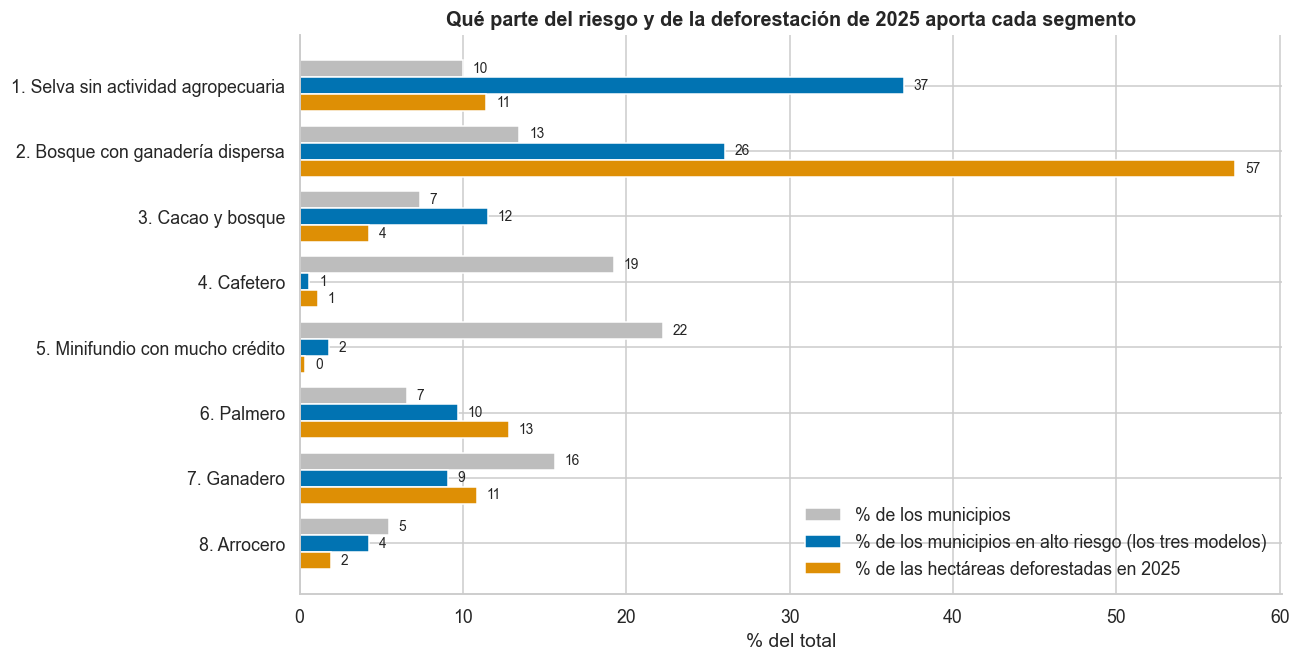

In [2]:
for n in NOMS:
    D[f"alto|{n}"] = D[n] >= D[n].quantile(CUANTIL_ALTO)
D["alto_tres"] = D[[f"alto|{n}" for n in NOMS]].all(axis=1)
D["alto_alguno"] = D[[f"alto|{n}" for n in NOMS]].any(axis=1)

g = D.groupby("nombre_segmento", observed=True)
res = pd.DataFrame({
    "municipios": g.size(),
    "% de los municipios": 100 * g.size() / len(D),
    "% deforestó en 2025": 100 * g.deforesta.mean(),
    **{f"riesgo medio {CORTO[n]}": g[n].mean() for n in NOMS},
    **{f"% en alto riesgo {CORTO[n]}": 100 * g[f"alto|{n}"].mean() for n in NOMS},
    "% en alto riesgo (los tres)": 100 * g.alto_tres.mean(),
    "municipios en alto riesgo (los tres)": g.alto_tres.sum(),
    "% del alto riesgo (los tres)": 100 * g.alto_tres.sum() / D.alto_tres.sum(),
    "ha deforestadas 2025": g.ha_2025.sum(),
    "% de las ha 2025": 100 * g.ha_2025.sum() / D.ha_2025.sum(),
    "% de las ha 2025 de su segmento en alto riesgo (los tres)": 100 * D[D.alto_tres].groupby("nombre_segmento", observed=True).ha_2025.sum().reindex(g.size().index).fillna(0) / g.ha_2025.sum(),
}).reindex(ORDEN)
display(res.round(1))

fig, ax = plt.subplots(figsize=(12, 6.2))
y = np.arange(len(res))[::-1]
h = 0.26
ax.barh(y + h, res["% de los municipios"], h, color="#bdbdbd", label="% de los municipios")
ax.barh(y, res["% del alto riesgo (los tres)"], h, color=sns.color_palette("colorblind")[0], label="% de los municipios en alto riesgo (los tres modelos)")
ax.barh(y - h, res["% de las ha 2025"], h, color=sns.color_palette("colorblind")[1], label="% de las hectáreas deforestadas en 2025")
for yi, a, b, d in zip(y, res["% de los municipios"], res["% del alto riesgo (los tres)"], res["% de las ha 2025"]):
    ax.text(a + 0.6, yi + h, f"{a:.0f}", va="center", fontsize=9)
    ax.text(b + 0.6, yi, f"{b:.0f}", va="center", fontsize=9)
    ax.text(d + 0.6, yi - h, f"{d:.0f}", va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(res.index)
ax.set_xlabel("% del total")
ax.set_title("Qué parte del riesgo y de la deforestación de 2025 aporta cada segmento")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "segmentos_y_riesgo_concentracion.png", dpi=160, bbox_inches="tight")
plt.show()

In [3]:
orden_ha = res.sort_values("% de las ha 2025", ascending=False)
top3 = orden_ha.head(3)
orden_riesgo = res.sort_values("% en alto riesgo (los tres)", ascending=False)
alto = orden_riesgo.head(3)
bajo = orden_riesgo.tail(2)
cota_alta = res[res["% en alto riesgo (los tres)"] >= 40]
cota_baja = res[res["% en alto riesgo (los tres)"] <= 10]
display(Markdown(
    f"**Qué se ve.**\n\n"
    f"- **Tres segmentos aportan el {top3['% de las ha 2025'].sum():.0f} % de las hectáreas deforestadas en 2025** con el {top3['% de los municipios'].sum():.0f} % de los municipios: "
    + "; ".join(f"{i[3:] if i[:2].strip('. ').isdigit() else i} ({v:.0f} %)" for i, v in top3["% de las ha 2025"].items()) + ".\n"
    f"- **Los segmentos con más municipios en alto riesgo para los tres modelos** son " + ", ".join(f"{i.split('. ',1)[-1].lower()} ({v:.0f} % de sus municipios)" for i, v in alto["% en alto riesgo (los tres)"].items())
    + ". Los de menos, " + " y ".join(f"{i.split('. ',1)[-1].lower()} ({v:.0f} %)" for i, v in bajo["% en alto riesgo (los tres)"].items()) + ".\n"
    f"- **{len(cota_alta)} segmento(s) tienen 4 de cada 10 municipios o más en alto riesgo** ({', '.join(i.split('. ',1)[-1].lower() for i in cota_alta.index) or 'ninguno'}); "
    f"**{len(cota_baja)} tienen 1 de cada 10 o menos** ({', '.join(i.split('. ',1)[-1].lower() for i in cota_baja.index) or 'ninguno'}).\n"
    f"- **El riesgo sí sigue de cerca al perfil.** El riesgo medio va de {res[[f'riesgo medio {CORTO[n]}' for n in NOMS]].mean(axis=1).min():.2f} a {res[[f'riesgo medio {CORTO[n]}' for n in NOMS]].mean(axis=1).max():.2f} entre segmentos (promedio de los tres modelos). "
    f"Pero eso no significa que el modelo solo repita el perfil: esa pregunta se responde en la sección 2."
))

**Qué se ve.**

- **Tres segmentos aportan el 82 % de las hectáreas deforestadas en 2025** con el 30 % de los municipios: Bosque con ganadería dispersa (57 %); Palmero (13 %); Selva sin actividad agropecuaria (11 %).
- **Los segmentos con más municipios en alto riesgo para los tres modelos** son selva sin actividad agropecuaria (95 % de sus municipios), bosque con ganadería dispersa (50 % de sus municipios), cacao y bosque (40 % de sus municipios). Los de menos, minifundio con mucho crédito (2 %) y cafetero (1 %).
- **3 segmento(s) tienen 4 de cada 10 municipios o más en alto riesgo** (selva sin actividad agropecuaria, bosque con ganadería dispersa, cacao y bosque); **2 tienen 1 de cada 10 o menos** (cafetero, minifundio con mucho crédito).
- **El riesgo sí sigue de cerca al perfil.** El riesgo medio va de 0.23 a 0.98 entre segmentos (promedio de los tres modelos). Pero eso no significa que el modelo solo repita el perfil: esa pregunta se responde en la sección 2.

**Lectura: el perfil concentra el riesgo, y el modelo acierta justo donde están las hectáreas (pregunta 1).**

*Las cifras de las lecturas de este notebook están copiadas de la corrida del 20/11/2026; las frases que imprime el propio notebook se generan solas.*

- **El riesgo sigue al perfil.** En selva deforestó el 100 % de los municipios en 2025 y el 95 % es de alto riesgo para los tres modelos; en bosque con ganadería dispersa, 87 % y 50 %; en cacao y bosque, 85 % y 40 %; en palmero, 91 % y 38 %. En el otro extremo, minifundio (21 % deforestó, 2 % de alto riesgo) y cafetero (65 % y 0,8 %).
- **Las hectáreas están en tres perfiles:** bosque con ganadería dispersa (57 %), palmero (13 %) y selva (11 %), el 82 % de las hectáreas con el 30 % de los municipios.
- **El modelo señala bien dentro del perfil.** En bosque con ganadería dispersa solo la mitad de los municipios (43 de 86) es de alto riesgo, y esa mitad tiene el **99 % de las hectáreas del segmento**; en selva 98 %, palmero 92 %, cacao y bosque 87 %, ganadero 84 % y arrocero 73 %. Aunque ese perfil tenga contornos poco nítidos en la segmentación (silueta de 0,12), el riesgo se decide municipio a municipio y el modelo
  lo resuelve.
- **Cuidado:** el perfil solo ya ordena con un AUC de 0,81 (ver la sección 2), así que buena parte del riesgo es del tipo de municipio y no del modelo.

### 1.1 Los perfiles en términos de *odds*

El *odds* es la razón entre los que deforestan y los que no: **deforestan / no deforestan**. "1 de cada 2" es un *odds* de 1; dos que deforestan por cada uno que no, un *odds* de 2.

Para cada perfil se muestra:

- el ***odds* de deforestar en 2025**, y el de todos los demás municipios;
- la **razón de *odds* frente al resto**: cuántas veces es mayor el *odds* en ese perfil que fuera de él, con su intervalo de confianza del 95 % (método de Woolf; si alguna casilla de la tabla 2×2 es cero se suma 0,5 a las cuatro y se marca con `*`);
- **dentro del perfil**, cuántos de los municipios de alto riesgo según los tres modelos deforestaron y cuántos no, y el *odds* del resto del perfil. Así se ve cuánto cambia la chance de deforestar cuando los modelos marcan un municipio, sin cambiar de perfil.

Si un denominador es cero (ningún municipio sin deforestar), el *odds* queda vacío; no se inventa un valor.

Todos los municipios: deforestan 410 y no 229; odds = 1.79.


,municipios,deforestan,no deforestan,odds del perfil,odds del resto,razón de odds frente al resto,IC inf,IC sup,con corrección *,alto riesgo (los tres): municipios,alto riesgo: deforestan,alto riesgo: no deforestan,resto del perfil: deforestan,resto: no deforestan,odds en el resto del perfil
segmento,,,,,,,,,,,,,,,
1. Selva sin actividad agropecuaria,64,64,0,NaN,1.51,85.44,5.26,1387.71,True,61,61,0,3,0,NaN
2. Bosque con ganadería dispersa,86,75,11,6.82,1.54,4.44,2.30,8.55,False,43,43,0,32,11,2.91
3. Cacao y bosque,47,40,7,5.71,1.67,3.43,1.51,7.79,False,19,19,0,21,7,3.00
4. Cafetero,123,80,43,1.86,1.77,1.05,0.69,1.58,False,1,1,0,79,43,1.84
5. Minifundio con mucho crédito,142,30,112,0.27,3.25,0.08,0.05,0.13,False,3,3,0,27,112,0.24
6. Palmero,42,38,4,9.50,1.65,5.75,2.02,16.31,False,16,16,0,22,4,5.50
7. Ganadero,100,60,40,1.50,1.85,0.81,0.52,1.25,False,15,15,0,45,40,1.12
8. Arrocero,35,23,12,1.92,1.78,1.07,0.52,2.20,False,7,7,0,16,12,1.33


Municipios de alto riesgo para los tres modelos: 165; de ellos NO deforestaron: 0. Como no hay ninguno, el odds en alto riesgo no se puede calcular (denominador cero).


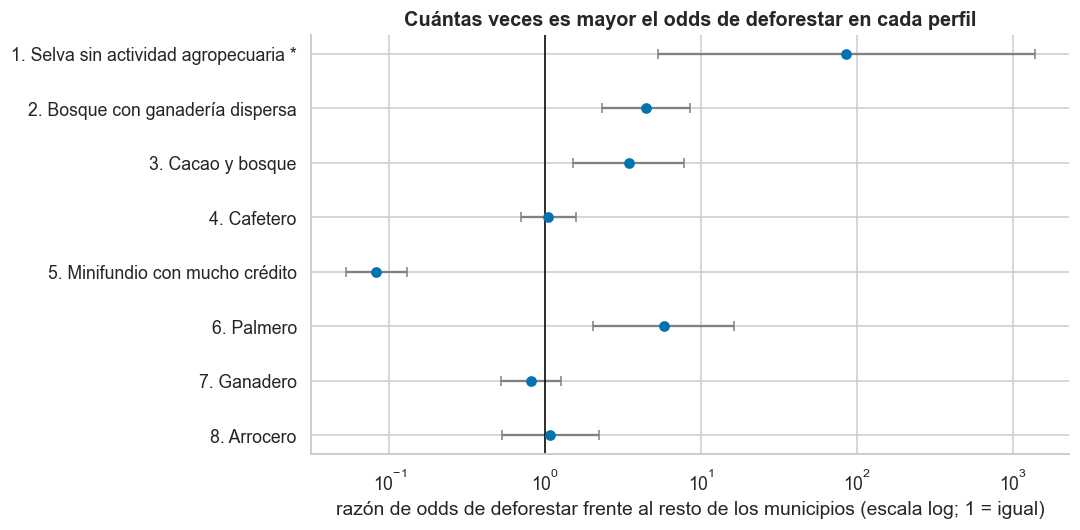

In [4]:
def odds(a, b):
    return a / b if b > 0 else np.nan


filas = []
for s in ORDEN:
    d = D[D.nombre_segmento == s]
    r = D[D.nombre_segmento != s]
    a, b = int(d.deforesta.sum()), int(len(d) - d.deforesta.sum())      # perfil: deforestan / no
    c, e = int(r.deforesta.sum()), int(len(r) - r.deforesta.sum())      # resto: deforestan / no
    corregido = min(a, b, c, e) == 0
    aa, bb, cc, ee = (a + 0.5, b + 0.5, c + 0.5, e + 0.5) if corregido else (a, b, c, e)
    rd = (aa * ee) / (bb * cc)
    se = np.sqrt(1 / aa + 1 / bb + 1 / cc + 1 / ee)
    alto, resto_seg = d[d.alto_tres], d[~d.alto_tres]
    filas.append({"segmento": s, "municipios": len(d), "deforestan": a, "no deforestan": b,
                  "odds del perfil": odds(a, b), "odds del resto": odds(c, e),
                  "razón de odds frente al resto": rd, "IC inf": np.exp(np.log(rd) - 1.96 * se), "IC sup": np.exp(np.log(rd) + 1.96 * se),
                  "con corrección *": corregido,
                  "alto riesgo (los tres): municipios": len(alto), "alto riesgo: deforestan": int(alto.deforesta.sum()),
                  "alto riesgo: no deforestan": int(len(alto) - alto.deforesta.sum()),
                  "resto del perfil: deforestan": int(resto_seg.deforesta.sum()), "resto: no deforestan": int(len(resto_seg) - resto_seg.deforesta.sum()),
                  "odds en el resto del perfil": odds(int(resto_seg.deforesta.sum()), int(len(resto_seg) - resto_seg.deforesta.sum()))})
ODDS_PERFIL = pd.DataFrame(filas).set_index("segmento")
n_pos_t, n_neg_t = int(D.deforesta.sum()), int(len(D) - D.deforesta.sum())
print(f"Todos los municipios: deforestan {n_pos_t} y no {n_neg_t}; odds = {odds(n_pos_t, n_neg_t):.2f}.")
display(ODDS_PERFIL.round(2))
sin_deforestar_alto = int(ODDS_PERFIL["alto riesgo: no deforestan"].sum())
print(f"Municipios de alto riesgo para los tres modelos: {int(ODDS_PERFIL['alto riesgo (los tres): municipios'].sum())}; de ellos NO deforestaron: {sin_deforestar_alto}. "
      + ("Como no hay ninguno, el odds en alto riesgo no se puede calcular (denominador cero)." if sin_deforestar_alto == 0 else ""))

fig, ax = plt.subplots(figsize=(10, 5))
y_ = np.arange(len(ODDS_PERFIL))[::-1]
ax.errorbar(ODDS_PERFIL["razón de odds frente al resto"], y_,
            xerr=[ODDS_PERFIL["razón de odds frente al resto"] - ODDS_PERFIL["IC inf"], ODDS_PERFIL["IC sup"] - ODDS_PERFIL["razón de odds frente al resto"]],
            fmt="o", color=sns.color_palette("colorblind")[0], ecolor="gray", capsize=3)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_yticks(y_)
ax.set_yticklabels([s + (" *" if ODDS_PERFIL.loc[s, "con corrección *"] else "") for s in ODDS_PERFIL.index])
ax.set_xlabel("razón de odds de deforestar frente al resto de los municipios (escala log; 1 = igual)")
ax.set_title("Cuántas veces es mayor el odds de deforestar en cada perfil")
plt.tight_layout()
plt.show()

**Lectura: los perfiles en términos de *odds* (lo que pidió el tutor).**

- **El perfil, solo, separa mucho en unos tipos y nada en otros.** El *odds* de deforestar de todos los municipios es 1,79. Es claramente mayor que en el resto en palmero (9,50; razón de 5,75, intervalo de 2,02 a 16,31), bosque con ganadería dispersa (6,82; razón de 4,44, de 2,30 a 8,55) y cacao y bosque (5,71; razón de 3,43, de 1,51 a 7,79). En selva deforestan los 64, así que su *odds* no se puede calcular; con la corrección de 0,5 la razón es 85, pero el intervalo va de 5 a 1.388: es mayor, y la cifra no es fiable. Minifundio es el contrario: *odds* de 0,27 y razón de 0,08 (de 0,05 a 0,13), más de diez veces menor que el resto. En cafetero (1,05), arrocero (1,07) y ganadero (0,81) el intervalo incluye 1: el perfil, por sí solo, no cambia la chance de deforestar. Ahí es donde decide el modelo.
- **Dentro del perfil, los municipios de alto riesgo para los tres modelos deforestaron todos.** Son 165 y ninguno dejó de deforestar, en todos los perfiles: 61 en selva, 43 en bosque con ganadería dispersa, 19 en cacao y bosque, 16 en palmero, 15 en ganadero, 7 en arrocero, 3 en minifundio y 1 en cafetero. Por eso su *odds* no se puede calcular (denominador cero). No significa que todo el que deforesta esté en la lista: los otros 245 de los 410 que deforestaron quedan fuera.
- **El resto del perfil queda por debajo del perfil completo.** Sin los marcados, el *odds* es 2,91 en bosque con ganadería dispersa (32 deforestan y 11 no), 3,00 en cacao y bosque, 5,50 en palmero, 1,84 en cafetero, 1,33 en arrocero, 0,24 en minifundio y 1,12 en ganadero (45 contra 40). En ganadero, una vez separados los 15 marcados, el resto queda casi en 1 a 1: es el perfil donde un criterio adicional (el historial de hectáreas, el crédito) tiene más espacio para ayudar a decidir.
- **Cautela.** Son *odds* de 2025 con pocos municipios por perfil, por eso los intervalos son anchos. Describen asociación, no causas.

## 2. ¿Los modelos aportan algo más que el perfil?

**La pregunta.** Si el riesgo sigue tanto al perfil, ¿para qué sirve el modelo? La respuesta depende de una prueba sencilla: **dentro de un mismo segmento**, ¿el modelo da más riesgo a los municipios que sí deforestaron que a los que no?

**Cómo se hace.**

- Para cada segmento y cada modelo se calcula el **AUC** (de 0,5, que es como tirar una moneda, a 1, que es ordenar perfecto) usando solo los municipios de ese segmento. Se acompaña de un intervalo del 95 % por remuestreo (500 veces), porque los segmentos son pequeños. Si un segmento tiene menos de 5 municipios de alguna de las dos clases (deforestó o no), no se calcula, porque la cifra no diría nada.
- Como **vara de comparación** se usa una regla que solo conoce el perfil: darle a cada municipio el % de años de 2021 a 2024 en que deforestaron los municipios de su segmento. Esa regla no ve nada del municipio, solo de su segmento. Si el modelo gana a esa regla, es porque ve algo más que el perfil.
- Se resume el AUC dentro de los segmentos en una sola cifra, ponderando cada segmento por el número de parejas (un municipio que deforestó y uno que no) que tiene. Así queda **fuera la comparación entre segmentos**, que es justo la que hace el perfil.

**Cómo leer el gráfico.** Cada punto es el AUC de un modelo dentro de un segmento; la línea es su intervalo del 95 %. Más a la derecha es mejor. La línea punteada en 0,5 es el azar. Si el intervalo cruza el 0,5, en ese segmento el modelo no se distingue del azar.

modelo,no deforestaron (de los que son),Gradient boosting,Random forest,Regresión logística
segmento,,,,
1. Selva sin actividad agropecuaria,0,NaN,NaN,NaN
2. Bosque con ganadería dispersa,11,0.91,0.92,0.87
3. Cacao y bosque,7,0.92,0.93,0.91
4. Cafetero,43,0.82,0.80,0.80
5. Minifundio con mucho crédito,112,0.90,0.91,0.84
6. Palmero,4,NaN,NaN,NaN
7. Ganadero,40,0.89,0.89,0.83
8. Arrocero,12,0.93,0.93,0.91


,AUC con todos los municipios (2025),AUC solo dentro de los segmentos (ponderado)
Gradient boosting,0.930,0.871
Random forest,0.930,0.871
Regresión logística,0.906,0.833
Solo perfil (vara de comparación),0.809,0.500


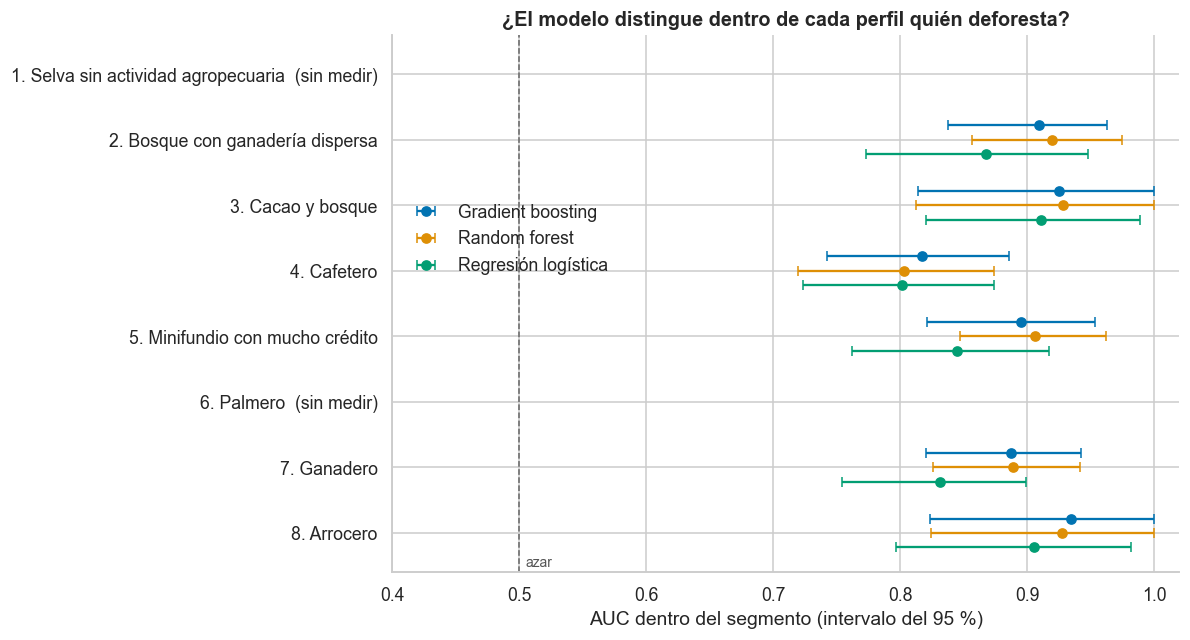

In [5]:
rng = np.random.default_rng(SEMILLA)


def auc_con_ic(y, p, B=500):
    y = np.asarray(y).astype(int)
    p = np.asarray(p)
    base = roc_auc_score(y, p)
    n = len(y)
    v = []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if y[i].min() == y[i].max():
            continue
        v.append(roc_auc_score(y[i], p[i]))
    lo, hi = np.percentile(v, [2.5, 97.5])
    return base, lo, hi


# Regla de "solo perfil": % de municipios-año de 2021-2024 con deforestación en el segmento
hist = panel[panel.anio.between(2021, 2024) & panel.tasa_def_ideam.notna()].merge(seg[["cod_dane", "nombre_segmento"]], on="cod_dane", how="inner")
perfil_hist = (hist.assign(def_=hist.tasa_def_ideam > 0).groupby("nombre_segmento", observed=True).def_.mean())
D["solo_perfil"] = D.nombre_segmento.map(perfil_hist)

filas = []
for s in ORDEN:
    d = D[D.nombre_segmento == s]
    pos, neg = int(d.deforesta.sum()), int((1 - d.deforesta).sum())
    for n in NOMS:
        if min(pos, neg) < 5:
            filas.append({"segmento": s, "modelo": n, "municipios": len(d), "deforestaron": pos, "no deforestaron": neg,
                          "AUC": np.nan, "IC inf": np.nan, "IC sup": np.nan, "pares": 0})
            continue
        a, lo, hi = auc_con_ic(d.deforesta, d[n])
        filas.append({"segmento": s, "modelo": n, "municipios": len(d), "deforestaron": pos, "no deforestaron": neg,
                      "AUC": a, "IC inf": lo, "IC sup": hi, "pares": pos * neg})
AUC_DENTRO = pd.DataFrame(filas)
tabla_auc = AUC_DENTRO.pivot(index="segmento", columns="modelo", values="AUC").reindex(ORDEN)[NOMS]
tabla_auc.insert(0, "no deforestaron (de los que son)", AUC_DENTRO.drop_duplicates("segmento").set_index("segmento")["no deforestaron"].reindex(ORDEN))
display(tabla_auc.round(2))

medibles = AUC_DENTRO.dropna(subset=["AUC"])
auc_ponderado = {n: np.average(medibles[medibles.modelo == n].AUC, weights=medibles[medibles.modelo == n].pares) for n in NOMS}
auc_global = {n: roc_auc_score(D.deforesta, D[n]) for n in NOMS}
auc_perfil = roc_auc_score(D.deforesta, D.solo_perfil)
# La regla de "solo perfil" da el mismo valor a todos los municipios de un segmento: dentro de un segmento empata siempre, y su AUC es 0,5 por construcción
auc_perfil_dentro = 0.5
comparacion = pd.DataFrame({"AUC con todos los municipios (2025)": {**auc_global, "Solo perfil (vara de comparación)": auc_perfil},
                            "AUC solo dentro de los segmentos (ponderado)": {**auc_ponderado, "Solo perfil (vara de comparación)": auc_perfil_dentro}})
display(comparacion.round(3))

fig, ax = plt.subplots(figsize=(11, 6))
y0 = np.arange(len(ORDEN))[::-1]
desp = {NOMS[0]: 0.22, NOMS[1]: 0.0, NOMS[2]: -0.22}
for n in NOMS:
    d = AUC_DENTRO[AUC_DENTRO.modelo == n].set_index("segmento").reindex(ORDEN)
    ok = d.AUC.notna().values
    ax.errorbar(d.AUC[ok], y0[ok] + desp[n], xerr=[(d.AUC - d["IC inf"])[ok], (d["IC sup"] - d.AUC)[ok]], fmt="o", color=COLOR[n],
                capsize=3, label=n, markersize=6)
ax.axvline(0.5, color="#666", ls="--", lw=1)
ax.text(0.505, -0.55, "azar", fontsize=9, color="#555", va="bottom")
ax.set_ylim(-0.6, len(ORDEN) - 0.4)
ax.set_yticks(y0)
ax.set_yticklabels([f"{s}" + ("  (sin medir)" if AUC_DENTRO[(AUC_DENTRO.segmento == s)].AUC.isna().all() else "") for s in ORDEN])
ax.set_xlim(0.4, 1.02)
ax.set_xlabel("AUC dentro del segmento (intervalo del 95 %)")
ax.set_title("¿El modelo distingue dentro de cada perfil quién deforesta?")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62), frameon=False)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "segmentos_y_riesgo_auc_dentro.png", dpi=160, bbox_inches="tight")
plt.show()

In [6]:
sin_medir = [s for s in ORDEN if AUC_DENTRO[AUC_DENTRO.segmento == s].AUC.isna().all()]
mejor_modelo = max(auc_ponderado, key=auc_ponderado.get)
prom = medibles.groupby("segmento").AUC.mean().sort_values()
cruzan = medibles[(medibles["IC inf"] <= 0.5)]
gana_a_perfil = [n for n in NOMS if auc_global[n] > auc_perfil]
display(Markdown(
    f"**Qué se ve.**\n\n"
    f"- **Los modelos ven algo más que el perfil.** Con todos los municipios, el AUC es de "
    + ", ".join(f"{auc_global[n]:.2f} ({CORTO[n]})" for n in NOMS)
    + f", frente a {auc_perfil:.2f} de la regla que solo conoce el perfil. "
    + (f"Los {len(gana_a_perfil)} modelos ganan a la regla de perfil. " if len(gana_a_perfil) == len(NOMS)
       else f"Ganan a la regla de perfil: {', '.join(gana_a_perfil) or 'ninguno'}. ")
    + f"Y **dentro de los segmentos**, donde la regla de perfil no puede distinguir (da 0,50 por construcción), el AUC ponderado de los modelos es de "
    + ", ".join(f"{auc_ponderado[n]:.2f} ({CORTO[n]})" for n in NOMS) + ". Es decir, distinguen entre municipios del mismo tipo.\n"
    + f"- **Dónde cuesta más:** {prom.index[0].split('. ',1)[-1].lower()} (AUC medio {prom.iloc[0]:.2f}); **dónde es más fácil:** {prom.index[-1].split('. ',1)[-1].lower()} ({prom.iloc[-1]:.2f}).\n"
    f"- **Segmentos sin poder medirse:** {', '.join(s.split('. ',1)[-1].lower() for s in sin_medir) or 'ninguno'}"
    + (" (casi todos sus municipios deforestaron en 2025, así que no hay con quién comparar y la cifra no diría nada)." if sin_medir else ".")
    + f"\n- **Intervalos que cruzan el azar:** {len(cruzan)} de {len(medibles)} combinaciones de modelo y segmento"
    + (": " + "; ".join(f"{CORTO[r.modelo]} en {r.segmento.split('. ',1)[-1].lower()}" for r in cruzan.itertuples()) if len(cruzan) else " (ninguna)") + ".\n\n"
    f"**Lo que significa.** El perfil dice en qué tipo de municipio se está; el modelo dice, **dentro de ese tipo**, cuáles tienen más riesgo. Los dos se complementan, y por eso se combinan en la lista de la sección 3."
))

**Qué se ve.**

- **Los modelos ven algo más que el perfil.** Con todos los municipios, el AUC es de 0.93 (GB), 0.93 (RF), 0.91 (LR), frente a 0.81 de la regla que solo conoce el perfil. Los 3 modelos ganan a la regla de perfil. Y **dentro de los segmentos**, donde la regla de perfil no puede distinguir (da 0,50 por construcción), el AUC ponderado de los modelos es de 0.87 (GB), 0.87 (RF), 0.83 (LR). Es decir, distinguen entre municipios del mismo tipo.
- **Dónde cuesta más:** cafetero (AUC medio 0.81); **dónde es más fácil:** arrocero (0.92).
- **Segmentos sin poder medirse:** selva sin actividad agropecuaria, palmero (casi todos sus municipios deforestaron en 2025, así que no hay con quién comparar y la cifra no diría nada).
- **Intervalos que cruzan el azar:** 0 de 18 combinaciones de modelo y segmento (ninguna).

**Lo que significa.** El perfil dice en qué tipo de municipio se está; el modelo dice, **dentro de ese tipo**, cuáles tienen más riesgo. Los dos se complementan, y por eso se combinan en la lista de la sección 3.

**Lectura: el modelo aporta más que el perfil, pero no igual en todos los tipos (pregunta 2).**

- **Más que el perfil.** La regla que solo conoce el perfil logra un AUC de 0,809 con todos los municipios y 0,50 dentro de los segmentos (por construcción). Los modelos logran 0,930, 0,930 y 0,906 con todos, y **0,871, 0,871 y 0,833 dentro de los segmentos**: distinguen entre municipios del mismo tipo.
- **Dónde cuesta y dónde es fácil.** Dentro del segmento el AUC va de 0,91-0,93 en arrocero y cacao y bosque, a 0,87-0,92 en bosque con ganadería dispersa, 0,84-0,91 en minifundio, 0,83-0,89 en ganadero y 0,80-0,82 en cafetero, el más difícil. La regresión logística queda unos 0,06 por debajo de los árboles en minifundio y ganadero.
- **Selva y palmero no se pueden medir:** no hay municipios que no deforestaron (0) o casi ninguno (4). No es que el modelo falle: no hay con quién comparar.
- **Intervalos.** Ninguno cruza el 0,5 (0 de 18 combinaciones), pero con 35 a 142 municipios son amplios; las diferencias de 0,02 o 0,03 entre segmentos no deben interpretarse.

### 2.1 ¿En qué perfiles se equivocan los modelos? Falsos positivos y falsos negativos por segmento

Con el umbral 0,5 de siempre, cuántos municipios de cada perfil son falsos negativos (deforestaron y no se marcaron) y falsos positivos (se marcaron y no deforestaron). Sirve para ver si el error se
concentra en algún tipo de municipio.

In [7]:
filas = []
for s in ORDEN:
    d = D[D.nombre_segmento == s]
    fila = {"segmento": s, "municipios": len(d), "deforestaron": int(d.deforesta.sum())}
    for n in NOMS:
        pred = (d[n] >= 0.5).astype(int)
        fila[f"FN {CORTO[n]}"] = int(((pred == 0) & (d.deforesta == 1)).sum())
        fila[f"FP {CORTO[n]}"] = int(((pred == 1) & (d.deforesta == 0)).sum())
    filas.append(fila)
errores_segmento = pd.DataFrame(filas).set_index("segmento")
display(errores_segmento)
fn_cols = [c for c in errores_segmento.columns if c.startswith("FN")]
fp_cols = [c for c in errores_segmento.columns if c.startswith("FP")]
print("Perfil con más falsos negativos (suma de los tres modelos):", errores_segmento[fn_cols].sum(axis=1).idxmax(),
      "· con más falsos positivos:", errores_segmento[fp_cols].sum(axis=1).idxmax())

,municipios,deforestaron,FN GB,FP GB,FN RF,FP RF,FN LR,FP LR
segmento,,,,,,,,
1. Selva sin actividad agropecuaria,64,64,0,0,0,0,0,0
2. Bosque con ganadería dispersa,86,75,5,6,3,6,2,8
3. Cacao y bosque,47,40,1,3,1,3,1,5
4. Cafetero,123,80,23,9,25,10,22,11
5. Minifundio con mucho crédito,142,30,11,3,12,4,18,6
6. Palmero,42,38,5,0,5,0,6,1
7. Ganadero,100,60,17,6,17,4,27,3
8. Arrocero,35,23,3,2,5,2,6,0


Perfil con más falsos negativos (suma de los tres modelos): 4. Cafetero · con más falsos positivos: 4. Cafetero


**Lectura: dónde se concentran los errores (falsos positivos y negativos por perfil).**

- **Los perfiles de más riesgo casi no tienen errores.** Con el gradient boosting, selva tiene 0 falsos negativos y 0 falsos positivos; bosque con ganadería dispersa 5 y 6; cacao y bosque 1 y 3; palmero 5 y 0. Entre los cuatro: 11 falsos negativos y 9 falsos positivos.
- **Los errores están en los perfiles de riesgo intermedio y bajo.** De los 65 falsos negativos, 54 (83 %) están en cafetero (23), ganadero (17), minifundio (11) y arrocero (3), perfiles que suman el 14 % de las hectáreas de 2025. El cafetero tiene además el mayor número de falsos positivos (9 de 29). Son municipios donde "deforestó" significa una pérdida pequeña (en cafetero deforestó el 65 %, con el 1,1 % de las hectáreas),
  así que el error está en el borde de "más de cero".
- **El ganadero merece atención.** Es el perfil de impacto (10,8 % de las hectáreas) donde el modelo más omite: 17 de los 60 municipios que deforestaron (28 %), y 27 con la regresión logística.

## 3. ¿Con qué municipios se empieza? Lista de prioridad

**La pregunta.** Con recursos limitados, ¿a qué municipios mirar primero, y qué decir de cada uno?

**Cómo se hace.** Cada municipio queda con su segmento y con un **riesgo de consenso**, el promedio de la probabilidad de los tres modelos. Se ordenan:

- **dentro de su segmento** (para saber cuáles son los más riesgosos de su tipo);
- y se marca si están en **alto riesgo para los tres modelos** (la señal más sólida).

Como hay muchos municipios con probabilidades casi iguales (cerca de 1) y diferencias de milésimas no dicen nada, **el riesgo de consenso se redondea a dos decimales (como se ve en la tabla) y, entre municipios con el mismo riesgo, el orden dentro del segmento desempata con las hectáreas deforestadas en 2021-2025**: primero el que más bosque ha perdido.

**Cómo leer la tabla.** Son los 3 municipios más prioritarios de cada segmento. La lista completa, con los 639, se guarda en `resultados/segmentos_y_riesgo_municipios.csv`.

In [8]:
# El riesgo de consenso se redondea a 2 decimales (lo que muestra la tabla): entre municipios con el mismo riesgo mostrado,
# va primero el que más hectáreas deforestó en 2021-2025. Sin redondear, diferencias de milésimas decidían el orden.
D["consenso_orden"] = D["consenso"].round(2)
D = D.sort_values(["nombre_segmento", "consenso_orden", "ha_2021_2025"], ascending=[True, False, False])
D["puesto en su segmento"] = D.groupby("nombre_segmento", observed=True).cumcount() + 1
D["modelos que lo ponen en alto riesgo"] = D[[f"alto|{n}" for n in NOMS]].sum(axis=1)

prioridad = (D[D["puesto en su segmento"] <= 3]
             .assign(segmento=lambda d: pd.Categorical(d.nombre_segmento, ORDEN, ordered=True))
             .sort_values(["segmento", "puesto en su segmento"])
             [["segmento", "puesto en su segmento", "nombre_municipio", "nombre_departamento", "consenso",
               "modelos que lo ponen en alto riesgo", "ha_2021_2025", "cred_km2"]]
             .rename(columns={"nombre_municipio": "municipio", "nombre_departamento": "departamento", "consenso": "riesgo de consenso",
                              "ha_2021_2025": "ha deforestadas 2021-2025", "cred_km2": "crédito (M$/km² al año)"}))
display(prioridad.round(2).reset_index(drop=True))

,segmento,puesto en su segmento,municipio,departamento,riesgo de consenso,modelos que lo ponen en alto riesgo,ha deforestadas 2021-2025,crédito (M$/km² al año)
0,1. Selva sin actividad agropecuaria,1,Cumaribo,Vichada,1.00,3,14334.62,0.14
1,1. Selva sin actividad agropecuaria,2,Mitú,Vaupés,1.00,3,2941.81,0.06
2,1. Selva sin actividad agropecuaria,3,Puerto Colombia (CD),Guainía,1.00,3,1692.75,0.00
3,2. Bosque con ganadería dispersa,1,Cartagena del Chairá,Caquetá,1.00,3,55725.31,1.55
4,2. Bosque con ganadería dispersa,2,Calamar,Guaviare,1.00,3,30142.94,0.35
5,2. Bosque con ganadería dispersa,3,San José del Guaviare,Guaviare,1.00,3,29724.00,1.36
6,3. Cacao y bosque,1,Barranco Minas (CD),Guainía,1.00,3,1441.12,0.01
7,3. Cacao y bosque,2,Santa Rosa del Sur,Bolívar,0.99,3,2570.25,4.60
8,3. Cacao y bosque,3,San Vicente de Chucurí,Santander,0.98,3,1167.88,28.91
9,4. Cafetero,1,El Tambo,Cauca,0.93,2,657.12,5.62


In [9]:
n_tres = int(D.alto_tres.sum())
ha_tres = 100 * D[D.alto_tres].ha_2021_2025.sum() / D.ha_2021_2025.sum()
satur = int((D.consenso >= 0.99).sum())
display(Markdown(
    f"**Qué se ve.**\n\n"
    f"- **{n_tres} municipios están en alto riesgo para los tres modelos a la vez** y concentran el {ha_tres:.0f} % de las hectáreas deforestadas entre 2021 y 2025. Es la lista corta más defendible: no depende de qué modelo se use.\n"
    f"- **{satur} municipios tienen un riesgo de consenso de 0,99 o más.** Entre ellos el modelo ya no distingue, porque casi todos deforestaron casi todos los años. Por eso el desempate por hectáreas importa: sirve para decidir por dónde empezar cuando la probabilidad ya no ayuda.\n"
    f"- La lista no dice que esos municipios \"sean culpables\" de nada. Dice **dónde conviene mirar primero**, con el perfil que explica por qué."
))

**Qué se ve.**

- **165 municipios están en alto riesgo para los tres modelos a la vez** y concentran el 95 % de las hectáreas deforestadas entre 2021 y 2025. Es la lista corta más defendible: no depende de qué modelo se use.
- **46 municipios tienen un riesgo de consenso de 0,99 o más.** Entre ellos el modelo ya no distingue, porque casi todos deforestaron casi todos los años. Por eso el desempate por hectáreas importa: sirve para decidir por dónde empezar cuando la probabilidad ya no ayuda.
- La lista no dice que esos municipios "sean culpables" de nada. Dice **dónde conviene mirar primero**, con el perfil que explica por qué.

**Lectura: la lista de prioridad y cómo se desempata.**

- **Es una lista defendible:** 165 municipios en alto riesgo para los tres modelos, que concentran el 95 % de las hectáreas de 2021-2025; 104 (63 %) son de selva o de bosque con ganadería dispersa. Por perfil: selva 61, bosque con ganadería dispersa 43, cacao y bosque 19, palmero 16, ganadero 15, arrocero 7, minifundio 3 y cafetero 1.
- **Entre los 46 con riesgo de consenso de 0,99 o más el modelo ya no distingue.** Ahí la lista sirve para identificar municipios, no para ordenarlos.
- **El desempate por hectáreas.** El orden redondea el riesgo de consenso a dos decimales y, entre municipios con el mismo riesgo, pone primero al que más hectáreas perdió en 2021-2025. Así, en bosque con ganadería dispersa la lista encabeza con Cartagena del Chairá (55.725 ha), seguida de Calamar (30.143 ha) y San José del Guaviare (29.724 ha); sin el redondeo iba primero Solano (21.368 ha) por una diferencia de milésimas. El redondeo es una decisión de diseño: dos municipios con 0,93 y 0,934 se tratan como empatados, que es lo que la tabla muestra. En los perfiles de riesgo medio (cafetero, arrocero) el orden pasa a depender de las hectáreas más que de diferencias mínimas de probabilidad.


## 4. ¿Dónde coinciden alto riesgo y alto crédito, y de qué perfil son?

**La pregunta.** El objetivo de negocio OBJ-N1 pide identificar dónde coinciden el financiamiento agropecuario alto y la deforestación alta. `comparacion_modelos.ipynb` los encuentra (sección 8). Aquí se agrega **a qué perfil pertenecen** y qué dice el crédito por km² de cada perfil.

**Cómo se hace.** Igual que allá: se llama *alto* al cuarto superior. Alto riesgo es el cuarto superior de la probabilidad de cada modelo. Alto crédito se mide de dos formas que cuentan cosas distintas:

- **Volumen**: millones de pesos de crédito de producción acumulados entre 2021 y 2025. Dice cuánta plata llega.
- **Intensidad**: millones por km² al año. Dice qué tan densa es esa plata en el territorio.

Un municipio grande de la frontera puede recibir mucho en volumen y casi nada por km².

**Cómo leer el gráfico.** Cada burbuja es un segmento. A la derecha, más crédito por km²; arriba, más municipios en alto riesgo para los tres modelos. El tamaño es el % de las hectáreas deforestadas en 2025. Si el riesgo estuviera donde el crédito es denso, las burbujas grandes estarían arriba a la derecha.

,en el cuarto superior de riesgo (los tres),con alto volumen de crédito,con alta intensidad de crédito,crédito mediano del segmento (M$/km² al año),% de las ha 2021-2025 de los que tienen alto volumen
nombre_segmento,,,,,
1. Selva sin actividad agropecuaria,57,1,0,0.3,2.5
2. Bosque con ganadería dispersa,39,13,0,4.8,29.6
3. Cacao y bosque,13,7,1,10.4,2.1
4. Cafetero,0,0,0,14.7,0.0
5. Minifundio con mucho crédito,1,1,0,30.4,0.1
6. Palmero,8,8,0,7.9,9.5
7. Ganadero,10,6,0,8.5,10.0
8. Arrocero,7,6,0,13.5,0.9


Comprobación: comparacion_modelos.ipynb reporta 42 municipios con alto riesgo y alto volumen en los tres modelos; aquí salen 42. OK


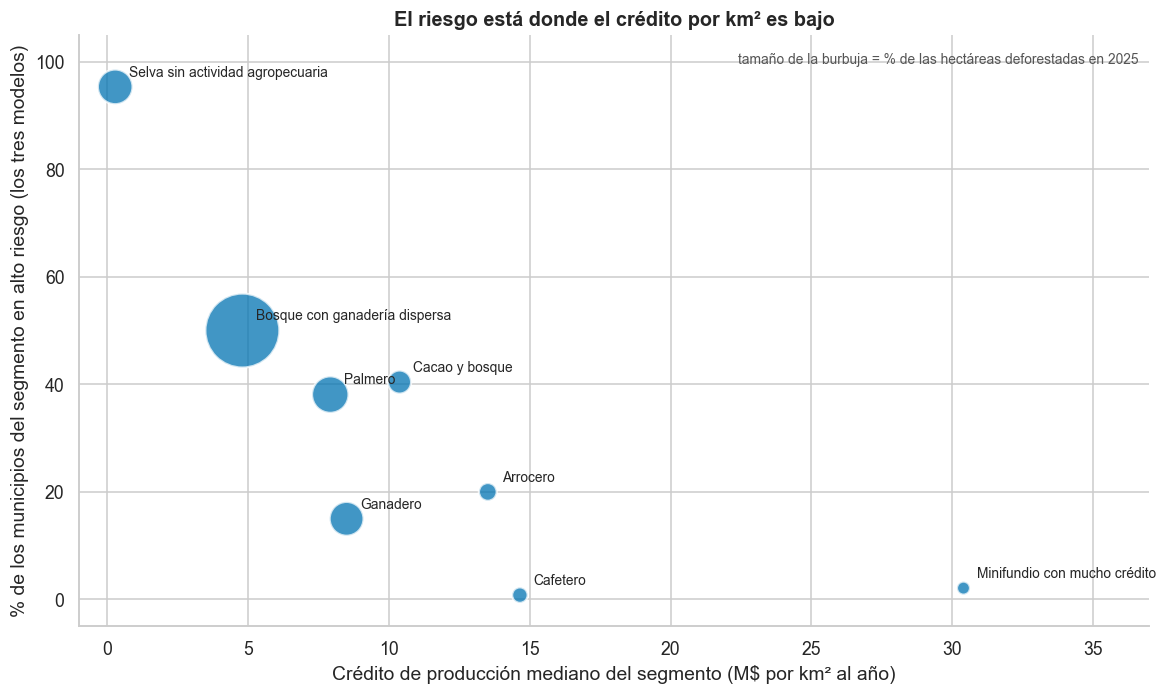

**Qué se ve.**

- **42 municipios combinan alto riesgo (en los tres modelos) y alto volumen de crédito**, y concentran el 55 % de las hectáreas deforestadas entre 2021 y 2025. En cambio, por intensidad (crédito por km²) solo coinciden 1.
- **Los perfiles donde más coinciden por volumen son** bosque con ganadería dispersa (13), palmero (8), cacao y bosque (7).
- **Entre perfiles, riesgo y crédito por km² van en sentido contrario** (correlación de Spearman entre los 8 segmentos: -0.86). Los perfiles con más crédito denso tienen poco riesgo, y los de más riesgo reciben poco crédito por km². Son solo 8 puntos: es una pista, no una prueba.

**Cuidado con la lectura.** Esto **no dice que el crédito proteja el bosque** ni que lo destruya. Los dos perfiles con más crédito por km² (minifundio con mucho crédito, cafetero) tienen un bosque mediano de 13 a 29 % del municipio, frente a 55-89 % en los dos de más riesgo (selva sin actividad agropecuaria, bosque con ganadería dispersa). La diferencia puede venir del tipo de actividad y del bosque que queda, no del crédito.

In [10]:
R = D.copy()
for n in NOMS:
    R[f"cuartil|{n}"] = R[n] >= R[n].quantile(CUANTIL_CREDITO)
alto_vol = R.credito_2021_2025_mm >= R.credito_2021_2025_mm.quantile(CUANTIL_CREDITO)
alto_int = R.cred_km2 >= R.cred_km2.quantile(CUANTIL_CREDITO)
riesgo_tres = R[[f"cuartil|{n}" for n in NOMS]].all(axis=1)
R["alto_riesgo_alto_volumen"] = riesgo_tres & alto_vol
R["alto_riesgo_alta_intensidad"] = riesgo_tres & alto_int
# El mismo criterio que comparacion_modelos: alto riesgo según cada modelo Y alto volumen, en los tres
R["_vol_tres"] = alto_vol & R[[f"cuartil|{n}" for n in NOMS]].all(axis=1)

cruce = pd.DataFrame({
    "en el cuarto superior de riesgo (los tres)": R.groupby("nombre_segmento", observed=True).apply(lambda d: int(d[[f"cuartil|{n}" for n in NOMS]].all(axis=1).sum())),
    "con alto volumen de crédito": R.groupby("nombre_segmento", observed=True).alto_riesgo_alto_volumen.sum(),
    "con alta intensidad de crédito": R.groupby("nombre_segmento", observed=True).alto_riesgo_alta_intensidad.sum(),
    "crédito mediano del segmento (M$/km² al año)": R.groupby("nombre_segmento", observed=True).cred_km2.median(),
    "% de las ha 2021-2025 de los que tienen alto volumen": 100 * R[R.alto_riesgo_alto_volumen].groupby("nombre_segmento", observed=True).ha_2021_2025.sum().reindex(ORDEN).fillna(0) / R.ha_2021_2025.sum(),
}).reindex(ORDEN)
display(cruce.round(1))

n_vol = int(R.alto_riesgo_alto_volumen.sum())
n_int = int(R.alto_riesgo_alta_intensidad.sum())
ha_vol = 100 * R[R.alto_riesgo_alto_volumen].ha_2021_2025.sum() / R.ha_2021_2025.sum()

# Verificación cruzada con la síntesis de comparacion_modelos.ipynb (que cuenta los municipios que cumplen en cada modelo por separado)
try:
    texto = " ".join(pd.read_csv(RUTA_SINTESIS).astype(str).agg(" ".join, axis=1))
    m = re.search(r"(\d+) municipios con alto riesgo y alto volumen", texto)
    if m:
        print(f"Comprobación: comparacion_modelos.ipynb reporta {m.group(1)} municipios con alto riesgo y alto volumen en los tres modelos; aquí salen {n_vol}.",
              "OK" if int(m.group(1)) == n_vol else "NO COINCIDE: revise qué corrida de cada notebook se está leyendo.")
except Exception as e:
    print("(No se pudo comparar con la síntesis de comparacion_modelos.ipynb:", e, ")")

pers = res["% en alto riesgo (los tres)"]
fig, ax = plt.subplots(figsize=(11, 6.5))
x = cruce["crédito mediano del segmento (M$/km² al año)"]
yv = res["% en alto riesgo (los tres)"]
sz = res["% de las ha 2025"] * 40 + 60
ax.scatter(x, yv, s=sz, color=sns.color_palette("colorblind")[0], alpha=0.75, edgecolor="white", linewidth=1.5)
for s_, xi, yi in zip(res.index, x, yv):
    ax.annotate(s_.split(". ", 1)[-1], (xi, yi), textcoords="offset points", xytext=(9, 7), fontsize=9)
ax.set_xlabel("Crédito de producción mediano del segmento (M$ por km² al año)")
ax.set_ylabel("% de los municipios del segmento en alto riesgo (los tres modelos)")
ax.set_title("El riesgo está donde el crédito por km² es bajo")
ax.set_ylim(-5, 105)
ax.set_xlim(-1, 37)
ax.text(0.99, 0.97, "tamaño de la burbuja = % de las hectáreas deforestadas en 2025", transform=ax.transAxes, ha="right", va="top", fontsize=9, color="#555")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "segmentos_y_riesgo_credito.png", dpi=160, bbox_inches="tight")
plt.show()

rho = pd.concat([x, yv], axis=1).corr("spearman").iloc[0, 1]
bosque_seg = seg.groupby("nombre_segmento", observed=True)["Bosque (% del municipio, 2021)"].median().rename("bosque")
top_cred = pd.concat([x.rename("cred"), bosque_seg], axis=1).sort_values("cred", ascending=False).head(2)
top_riesgo = pd.concat([yv.rename("riesgo"), bosque_seg], axis=1).sort_values("riesgo", ascending=False).head(2)
mas_vol = cruce.sort_values("con alto volumen de crédito", ascending=False).head(3)
display(Markdown(
    f"**Qué se ve.**\n\n"
    f"- **{n_vol} municipios combinan alto riesgo (en los tres modelos) y alto volumen de crédito**, y concentran el {ha_vol:.0f} % de las hectáreas deforestadas entre 2021 y 2025. "
    f"En cambio, por intensidad (crédito por km²) solo coinciden {n_int}.\n"
    f"- **Los perfiles donde más coinciden por volumen son** " + ", ".join(f"{i.split('. ',1)[-1].lower()} ({int(v)})" for i, v in mas_vol["con alto volumen de crédito"].items()) + ".\n"
    f"- **Entre perfiles, riesgo y crédito por km² van en sentido contrario** (correlación de Spearman entre los {len(res)} segmentos: {rho:+.2f}). "
    f"Los perfiles con más crédito denso tienen poco riesgo, y los de más riesgo reciben poco crédito por km². Son solo {len(res)} puntos: es una pista, no una prueba.\n\n"
    f"**Cuidado con la lectura.** Esto **no dice que el crédito proteja el bosque** ni que lo destruya. Los dos perfiles con más crédito por km² ({', '.join(i.split('. ',1)[-1].lower() for i in top_cred.index)}) "
    f"tienen un bosque mediano de {top_cred.bosque.min():.0f} a {top_cred.bosque.max():.0f} % del municipio, frente a {top_riesgo.bosque.min():.0f}-{top_riesgo.bosque.max():.0f} % en los dos de más riesgo "
    f"({', '.join(i.split('. ',1)[-1].lower() for i in top_riesgo.index)}). "
    f"La diferencia puede venir del tipo de actividad y del bosque que queda, no del crédito."
))

**Lectura: crédito y riesgo por perfil (pregunta 4; OBJ-N1, ODM-2).**

- **Por volumen sí coinciden: 42 municipios** de alto riesgo y alto volumen de crédito (igual que en la comparación de modelos). Por perfil: bosque con ganadería dispersa 13, palmero 8, cacao y bosque 7, ganadero 6 y arrocero 6. Los de bosque con ganadería dispersa tienen el 29,6 % de las hectáreas de 2021-2025 de todo el país rural; los ganaderos, 10,0 %, y los palmeros, 9,5 %.
- **Por intensidad casi no:** solo 1 municipio, de cacao y bosque. Los perfiles con crédito más denso (minifundio con 30,4 M$ por km² y cafetero con 14,7) tienen 1 y 0 municipios en alto riesgo; los que más riesgo tienen reciben poco por km² (selva 0,3, bosque con ganadería dispersa 4,8, palmero 7,9, ganadero 8,5).
  La correlación entre los 8 perfiles es de -0,86, pero son 8 puntos: una pista, no una prueba.
- **Cómo leerlo.** La coincidencia por volumen refleja sobre todo el **tamaño** de los municipios (los grandes reciben más plata en total), no densidad de crédito. Con la lectura exigente, la de intensidad, la coincidencia casi desaparece. OBJ-N1 se cumple por volumen, con esa advertencia, y sin afirmar nada sobre si el crédito causa o protege.

## 5. Síntesis: una lectura por segmento

**Cómo se hace.** La tabla junta lo anterior en una fila por segmento: el perfil, el riesgo, lo que aporta en hectáreas, cuánto crédito recibe y si el modelo agrega algo dentro de él. La última columna es una **lectura de uso** con una regla simple, aplicada a los números de la corrida:

- si casi todos los municipios del segmento deforestaron en 2025 (95 % o más), el riesgo es **generalizado**: la probabilidad ya no ayuda a escoger, y conviene priorizar por hectáreas;
- si el 40 % o más de sus municipios está en alto riesgo para los tres modelos, el riesgo está **concentrado** y el modelo ayuda a escoger cuáles primero;
- si el 10 % o menos lo está, el riesgo es **bajo**, y el modelo sirve para detectar las excepciones;
- en los demás casos el riesgo es **intermedio**, y es donde más ayuda el modelo para separar unos municipios de otros.

In [11]:
def lectura(fila):
    if fila["% deforestó en 2025"] >= 95:
        return "Riesgo generalizado: casi todos deforestan; priorizar por hectáreas, no por probabilidad."
    if fila["% en alto riesgo (los tres)"] >= 40:
        return "Riesgo concentrado: el modelo ayuda a escoger cuáles municipios primero."
    if fila["% en alto riesgo (los tres)"] <= 10:
        return "Riesgo bajo: el modelo sirve para detectar las excepciones."
    return "Riesgo intermedio: aquí el modelo es el que separa unos municipios de otros."


perfil_med = seg.groupby("nombre_segmento", observed=True).agg(**{
    "bosque (% del municipio)": ("Bosque (% del municipio, 2021)", "median"),
    "bovinos por km²": ("Bovinos por km²", "median")}).reindex(ORDEN)
sintesis = pd.DataFrame({
    "municipios": res["municipios"].astype(int),
    "bosque (% del municipio)": perfil_med["bosque (% del municipio)"],
    "bovinos por km²": perfil_med["bovinos por km²"],
    "crédito (M$/km² al año)": cruce["crédito mediano del segmento (M$/km² al año)"],
    "% deforestó en 2025": res["% deforestó en 2025"],
    "% en alto riesgo (los tres)": res["% en alto riesgo (los tres)"],
    "% de las ha 2025": res["% de las ha 2025"],
    "AUC dentro del segmento (promedio de los tres)": AUC_DENTRO.groupby("segmento").AUC.mean().reindex(ORDEN),
})
sintesis["lectura de uso"] = sintesis.apply(lectura, axis=1)
display(sintesis.round(1))

,municipios,bosque (% del municipio),bovinos por km²,crédito (M$/km² al año),% deforestó en 2025,% en alto riesgo (los tres),% de las ha 2025,AUC dentro del segmento (promedio de los tres),lectura de uso
1. Selva sin actividad agropecuaria,64,88.9,0.1,0.3,100.0,95.3,11.4,NaN,"Riesgo generalizado: casi todos deforestan; priorizar por hectáreas, no por probabilidad."
2. Bosque con ganadería dispersa,86,54.7,14.9,4.8,87.2,50.0,57.3,0.9,Riesgo concentrado: el modelo ayuda a escoger cuáles municipios primero.
3. Cacao y bosque,47,36.5,41.6,10.4,85.1,40.4,4.3,0.9,Riesgo concentrado: el modelo ayuda a escoger cuáles municipios primero.
4. Cafetero,123,28.9,26.0,14.7,65.0,0.8,1.1,0.8,Riesgo bajo: el modelo sirve para detectar las excepciones.
5. Minifundio con mucho crédito,142,13.2,51.3,30.4,21.1,2.1,0.3,0.9,Riesgo bajo: el modelo sirve para detectar las excepciones.
6. Palmero,42,9.9,57.9,7.9,90.5,38.1,12.8,NaN,Riesgo intermedio: aquí el modelo es el que separa unos municipios de otros.
7. Ganadero,100,8.3,68.7,8.5,60.0,15.0,10.8,0.9,Riesgo intermedio: aquí el modelo es el que separa unos municipios de otros.
8. Arrocero,35,6.6,53.8,13.5,65.7,20.0,1.9,0.9,Riesgo intermedio: aquí el modelo es el que separa unos municipios de otros.


In [12]:
lectura_n = sintesis["lectura de uso"].str.split(":").str[0].value_counts()
display(Markdown(
    "**Para llevar al documento.**\n\n"
    f"1. **El perfil explica dónde está el riesgo.** {top3['% de las ha 2025'].sum():.0f} % de las hectáreas de 2025 están en tres segmentos "
    f"({', '.join(i.split('. ',1)[-1].lower() for i in top3.index)}).\n"
    f"2. **El modelo agrega información dentro del perfil.** Con todos los municipios el AUC es de {min(auc_global.values()):.2f} a {max(auc_global.values()):.2f}, frente a {auc_perfil:.2f} de la regla que solo conoce el perfil; "
    f"y dentro de los segmentos, donde esa regla da 0,50, los modelos llegan a {min(auc_ponderado.values()):.2f}-{max(auc_ponderado.values()):.2f}.\n"
    f"3. **El uso depende del segmento.** " + "; ".join(f"{k.lower()}: {v} segmento(s)" for k, v in lectura_n.items()) + ".\n"
    f"4. **El riesgo no está donde el crédito es denso.** Entre segmentos, riesgo y crédito por km² tienen una correlación de {rho:+.2f}, y por volumen coinciden {n_vol} municipios.\n"
    f"5. **Es descriptivo.** No se afirma que el crédito cause ni evite la deforestación."
))

**Para llevar al documento.**

1. **El perfil explica dónde está el riesgo.** 82 % de las hectáreas de 2025 están en tres segmentos (bosque con ganadería dispersa, palmero, selva sin actividad agropecuaria).
2. **El modelo agrega información dentro del perfil.** Con todos los municipios el AUC es de 0.91 a 0.93, frente a 0.81 de la regla que solo conoce el perfil; y dentro de los segmentos, donde esa regla da 0,50, los modelos llegan a 0.83-0.87.
3. **El uso depende del segmento.** riesgo intermedio: 3 segmento(s); riesgo concentrado: 2 segmento(s); riesgo bajo: 2 segmento(s); riesgo generalizado: 1 segmento(s).
4. **El riesgo no está donde el crédito es denso.** Entre segmentos, riesgo y crédito por km² tienen una correlación de -0.86, y por volumen coinciden 42 municipios.
5. **Es descriptivo.** No se afirma que el crédito cause ni evite la deforestación.

**Lectura: qué hacer con cada perfil, combinando riesgo, solidez del perfil y crédito (ODM-2, OBJ-N1).**

*Son propuestas de uso derivadas de las cifras de este notebook y de la segmentación; no son resultados medidos.* La regla de la tabla (generalizado, concentrado, intermedio, bajo) es una guía con umbrales fijos; abajo se ajusta donde los números piden matiz.

- **Selva sin actividad agropecuaria** (riesgo generalizado; perfil firme, silueta 0,45). Todos deforestan y el 95 % es de alto riesgo, así que la probabilidad no ayuda a escoger: priorizar por **hectáreas** (Cumaribo, 14.335 ha). Casi no tiene crédito (0,3 M$ por km²): el instrumento es monitoreo, no financiamiento.
- **Bosque con ganadería dispersa** (concentrado; perfil de contornos difusos, silueta 0,12). Es el perfil de **mayor prioridad**: 57 % de las hectáreas de 2025, con el 99 % en los municipios de alto riesgo y un AUC de 0,87-0,92 dentro del segmento. Por la frontera difusa se trabaja por municipio, con el puntaje de riesgo (Cartagena del Chairá, Calamar, San José del Guaviare).
- **Cacao y bosque** (concentrado). 40 % de alto riesgo, AUC de 0,91-0,93 y el único perfil con un municipio donde coinciden riesgo alto y crédito denso. Pocas hectáreas (4,3 %): perfil para trazabilidad de la cadena más que para volumen.
- **Palmero** (la tabla lo marca intermedio; léase como alto). Su 38,1 % de alto riesgo está a menos de 2 puntos del umbral de 40 % para "concentrado", y su AUC no se puede medir (4 municipios sin deforestar), así que la frase "el modelo separa unos de otros" no se sostiene con datos. Lo que sí se ve: 91 % deforestó, 12,8 % de las hectáreas y 92 % de ellas en
  municipios de alto riesgo. Trabajar municipio a municipio (Mapiripán, 34.891 ha).
- **Ganadero** (intermedio; contornos difusos, silueta 0,21). El modelo ayuda (AUC de 0,83-0,89) pero omite el 28 % de los que deforestan. Conviene revisar el consenso de los tres modelos y el historial de hectáreas, no solo el puntaje de uno.
- **Arrocero** (intermedio). 20 % de alto riesgo y solo 1,9 % de las hectáreas, con el mejor AUC dentro del segmento (0,91-0,93): vigilancia selectiva guiada por el modelo.
- **Cafetero y minifundio** (bajo). 41 % de los municipios y el 1,4 % de las hectáreas de 2025. Son grupo de contraste. En cafetero el modelo es el menos preciso (AUC de 0,80-0,82, 23 falsos negativos), pero con pérdidas pequeñas.
- **Mensaje común:** el perfil dice **el tipo de acción** (monitoreo, trazabilidad, revisión del crédito ganadero) y el puntaje decide **el municipio**.

## 6. Limitaciones

- **Dos momentos distintos.** El segmento es el perfil promedio de 2021 a 2024, y el riesgo es el de 2025. Un municipio puede haber cambiado de perfil en 2025 sin que la segmentación lo registre.
- **"Deforestó" significa que perdió bosque en el año, aunque sea poco.** En los segmentos de selva y de bosque con mucha ganadería casi todos los municipios cumplen, así que la pregunta "¿deforesta?" deja de distinguir y hay que mirar las hectáreas.
- **Segmentos pequeños.** Con 35 a 142 municipios por segmento, los AUC tienen intervalos amplios. Se reportan con su intervalo para no sobreinterpretar.
- **Probabilidades casi iguales.** Los tres modelos dan casi 1 a muchos municipios, y entre ellos el orden lo decide el desempate por hectáreas.
- **Asociación, no causalidad.** Cruzar perfil, riesgo y crédito muestra dónde están las cosas, no por qué.
- **Depende de otras corridas.** El notebook solo lee lo que dejaron los demás; si cambia la segmentación o algún modelo, hay que volver a correr `comparacion_modelos.ipynb` y luego este.

## 7. Guardar resultados

In [13]:
salida_mun = (D.assign(segmento=lambda d: d.nombre_segmento)
              [["cod_dane", "nombre_municipio", "nombre_departamento", "region", "segmento", "puesto en su segmento",
                "consenso"] + NOMS + ["modelos que lo ponen en alto riesgo", "alto_tres", "deforesta", "ha_2025", "ha_2021_2025",
                                      "credito_2021_2025_mm", "cred_km2"]]
              .rename(columns={"nombre_municipio": "municipio", "nombre_departamento": "departamento", "consenso": "riesgo de consenso 2025",
                               "alto_tres": "alto riesgo (los tres)", "deforesta": "deforestó en 2025", "ha_2025": "ha deforestadas 2025",
                               "ha_2021_2025": "ha deforestadas 2021-2025", "credito_2021_2025_mm": "crédito de producción 2021-2025 (millones $)",
                               "cred_km2": "crédito (M$/km² al año)"})
              .sort_values(["segmento", "puesto en su segmento"]))
salida_mun.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_municipios.csv", index=False, encoding="utf-8-sig")
sintesis.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_sintesis.csv", encoding="utf-8-sig")
res.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_concentracion.csv", encoding="utf-8-sig")
AUC_DENTRO.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_auc_dentro.csv", index=False, encoding="utf-8-sig")
cruce.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_credito.csv", encoding="utf-8-sig")
errores_segmento.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_errores.csv", encoding="utf-8-sig")
ODDS_PERFIL.to_csv(DIR_RESULTADOS / "segmentos_y_riesgo_odds.csv", encoding="utf-8-sig")
print("Guardado en modelos y clusters/resultados/: segmentos_y_riesgo_{municipios, sintesis, concentracion, auc_dentro, credito, errores, odds}.csv")
print("Figuras en docs/figuras/: segmentos_y_riesgo_{concentracion, auc_dentro, credito}.png")

Guardado en modelos y clusters/resultados/: segmentos_y_riesgo_{municipios, sintesis, concentracion, auc_dentro, credito, errores, odds}.csv
Figuras en docs/figuras/: segmentos_y_riesgo_{concentracion, auc_dentro, credito}.png
